# The v5 engine vs the v4 engine — the forced-win layer on a common trajectory

## Goal

Measure the shipped v5 engine — `vcf.search_v5` (connect6/vcf.py): the v4 search plus the
forced-win layer (docs/EVALUATION.md, section 11) — against the v4 engine it extends. Both
engines answer the same recorded game: `benchmarks/trajectory.json`, a 48-move game played
by v4 against itself, loaded here from its stored copy (the v4 notebook generates that
game and verifies the stored copy against it). At every one of the game's 48 decision
points both engines choose a move, and this notebook compares their answers, their scores
and what each answer cost in examined nodes (`harness.analyze_history`, one worker process
per position and engine). The position battery (section 11.3) proves the layer's skills
end to end; this notebook measures, move by move, where the extra machinery changes the
engine's mind and what it costs.

Weights are pinned to `tuning/winner.json`, the shipped tuned weight set. Both engines are
deterministic, so node counts, scores and moves reproduce docs/EVALUATION.md, section 11.3
exactly; wall milliseconds are measured while twelve worker processes share the machine,
so they are indicative only — the exact, reproducible record is node counts.

## Expected behaviour

The layer must (1) answer every proven-win position of the trajectory's closing stretch in
exactly one node — stage 1 returns before any tree search runs, (2) give six answers in
the proven-win band where v4's answers stay in the unproven middle of the scale: five
one-node stage-1 answers (prefixes 42, 44, 45, 46, 47) plus a sixth stage-1 proof needing
70 nodes (prefix 36), (3) change 35 of 48 moves — 30 of them the deepening loop's choices
on ordinary positions, five the stage-1 answers themselves (six answers, one coinciding
with v4's move) — and (4) pay for it: 4.4x v4's mean node count (29,486 vs 6,667), with
the deepening budget's overshoot reaching 233,374 nodes on the sharpest position (prefix
34: a floor tree just below the budget launches a depth-4 iteration that runs to
completion at 220,243 nodes). The stage-2 probe below replays the deepening loop in
isolation and pins the decomposition: the budget buys changed moves on ordinary positions,
never a changed verdict.

Runtime: about 8 minutes (the 96 engine analyses and the 48-position deepening probe run
on 12 worker processes; loading the stored game is instant).

## The two engines, in plain words

Both engines answer the same question — given this board and this side to move, which
pair of stones should we place? — with the same board evaluator and the same alpha-beta
tree search at their core. They differ in what wraps that core:

- **v4** answers with a single fixed-depth tree search. It always searches to depth 3,
  enhanced with *quiescence* (the search keeps following forcing moves beyond the depth
  limit, so it never has to evaluate a position in the middle of a tactical sequence) and
  *forward pruning* (only the most promising move candidates are expanded). One tree,
  one answer.

- **v5** wraps the same core in a three-step procedure (`connect6/vcf.py`), referred to
  throughout as **stage 1, stage 2, stage 3**:

  1. **Stage 1 — the forced-win search.** Before any tree search runs, a narrow, exact
     search examines only forcing moves: can our side build an unbroken chain of threats
     the opponent cannot escape? If yes, the winning pair is returned immediately with a
     proven-win score (+20,000 for Black if it is Black to move, -20,000 for White).
     If no chain can be proven within this stage's limits, it gives up quickly and the
     next stage runs.
  2. **Stage 2 — the tree search with a node budget.** The v4 search runs at the *depth
     floor* (the configuration's base depth, 3). Then it *deepens*: it re-searches one
     ply deeper, then two plies deeper (at most `V5_DEEPEN_STEPS = 2` extra plies), as
     long as the *cumulative* node count of all iterations stays under
     `V5_NODE_BUDGET = 12000`. The budget is checked between iterations — an iteration
     that has started always runs to completion, so a position's total can overshoot.
  3. **Stage 3 — the defence screen.** The move chosen by stage 2 is checked before it
     is played: if it would hand the opponent a proven forced win (or leave a specific
     two-stone threat shape that would force our entire next reply), a safer candidate
     is chosen instead.

Vocabulary used below, defined once here:

- **decision point** — one position of the recorded game where a move is to be made; the
  48-move game provides 48 decision points, identified by *prefix* (the position after N
  moves of the game).
- **node** — one board position examined by a tree search. **Node count** is the exact,
  reproducible measure of what a search cost; wall time varies with the machine.
- **verdict band** — the terminal band of the evaluator's scale: a score of +20,000 or
  more is a proven win for Black, -20,000 or less a proven win for White. A **verdict
  flip** between two engines means one answers inside the proven-win band where the
  other stays in the unproven middle of the scale.
- **ordinary position / ordinary move** — a position with no immediate forcing threats
  (the regular moves of a regular game), as opposed to tactical ones. The evaluation
  document calls these *quiet* positions.
- **one-node answer** — a position where stage 1 returns the winning pair immediately:
  the entire answer cost a single examined node.

In [1]:
import os
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.search import search_alpha_beta_with_quiescence
from connect6.vcf import search_v5

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)


## The common trajectory

The recorded game is prepared data: `benchmarks/trajectory.json`, a 48-move v4-vs-v4
self-play (the game of section 10.2), generated and verified in the v4 notebook and
loaded here without regenerating. One game, 48 decision points, shared by the v4, v5 and
v6 measurements — every version comparison in this story is measured on the same game.

In [2]:
import json

record = json.loads((ROOT / "benchmarks" / "trajectory.json").read_text())
history = record["history"]
assert record["outcome"] == {"winner": None, "plies": 48}
assert history[0] == "JJ" and len(history) == 49
print("common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap")


rows = harness.analyze_history(history, [("v4", search_alpha_beta_with_quiescence), ("v5", search_v5)], 3)
per_prefix = {}
for row in rows:
    per_prefix.setdefault(row.prefix, {})[row.name] = row
positions = sorted(per_prefix)
n = len(positions)

totals = {name: sum(per_prefix[p][name].nodes for p in positions) for name in ("v4", "v5")}
changes = sum(1 for p in positions if per_prefix[p]["v4"].move != per_prefix[p]["v5"].move)
flips = sum(1 for p in positions if (abs(per_prefix[p]["v4"].score) >= 20000) != (abs(per_prefix[p]["v5"].score) >= 20000))
ones = [p for p in positions if per_prefix[p]["v5"].nodes == 1]
peak = max(positions, key=lambda p: per_prefix[p]["v5"].nodes)
print(f"{'engine':6s} {'total nodes':>12s} {'mean/position':>13s} {'peak':>8s}")
for name in ("v4", "v5"):
    top = max(per_prefix[p][name].nodes for p in positions)
    print(f"{name:6s} {totals[name]:12,d} {totals[name] // n:13,d} {top:8,d}")
print(f"move changes: {changes}/{n}   verdict-band flips: {flips}/{n}   v5 node peak: prefix {peak}")
print(f"one-node stage-1 answers: {ones}")
for p in ones:
    row = per_prefix[p]
    print(f"  prefix {p:2d}: v5 answers {row['v5'].move} at {row['v5'].score} in one node; "
          f"v4 scored {row['v4'].score} in {row['v4'].nodes:,} nodes")

common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap


engine  total nodes mean/position     peak
v4          320,038         6,667   40,262
v5        1,415,330        29,486  233,374
move changes: 35/48   verdict-band flips: 6/48   v5 node peak: prefix 34
one-node stage-1 answers: [42, 44, 45, 46, 47]
  prefix 42: v5 answers IMJM at 20000 in one node; v4 scored 441 in 9,689 nodes
  prefix 44: v5 answers IMJM at 20000 in one node; v4 scored 1961 in 4,808 nodes
  prefix 45: v5 answers FKFJ at -20000 in one node; v4 scored -278 in 11,979 nodes
  prefix 46: v5 answers IMJM at 20000 in one node; v4 scored 474 in 21,722 nodes
  prefix 47: v5 answers FKFJ at -20000 in one node; v4 scored -561 in 9,514 nodes


In [3]:
EXPECTED_V5 = {"v4_nodes": 320038, "v5_nodes": 1415330, "changes": 35, "flips": 6, "ones": [42, 44, 45, 46, 47], "v5_peak": 233374}
assert totals["v4"] == EXPECTED_V5["v4_nodes"]
assert totals["v5"] == EXPECTED_V5["v5_nodes"]
assert changes == EXPECTED_V5["changes"]
assert flips == EXPECTED_V5["flips"]
assert ones == EXPECTED_V5["ones"]
assert max(per_prefix[p]["v5"].nodes for p in positions) == EXPECTED_V5["v5_peak"]
assert per_prefix[36]["v5"].score == 20000 and per_prefix[36]["v5"].nodes == 70
print("the layer's costs and verdicts reproduce section 11.3 exactly (nodes, changes, flips, one-node answers)")


the layer's costs and verdicts reproduce section 11.3 exactly (nodes, changes, flips, one-node answers)


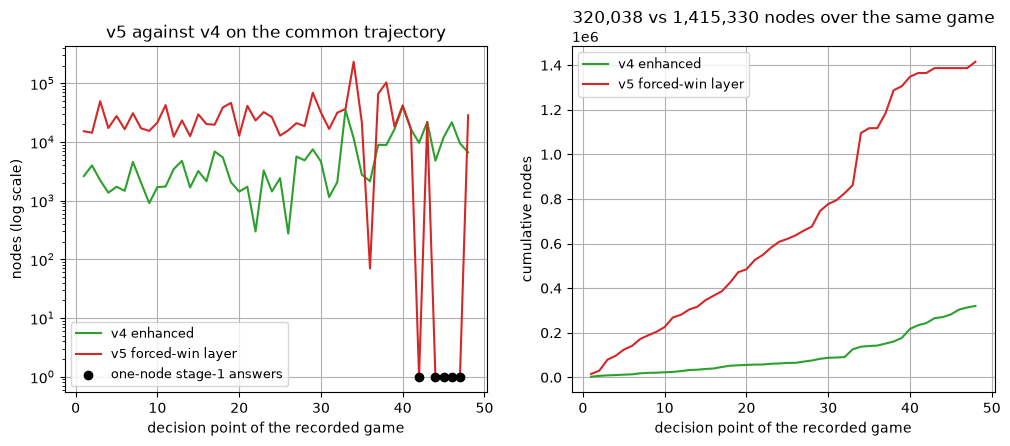

In [4]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v4"].nodes for p in positions], color="tab:green", label="v4 enhanced")
ax.plot(positions, [per_prefix[p]["v5"].nodes for p in positions], color="tab:red", label="v5 forced-win layer")
ax.scatter(ones, [1] * len(ones), color="black", zorder=3, label="one-node stage-1 answers")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("v5 against v4 on the common trajectory")
ax.grid(True)
ax.legend(fontsize=9)
ax2.plot(positions, [sum(per_prefix[q]["v4"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:green", label="v4 enhanced")
ax2.plot(positions, [sum(per_prefix[q]["v5"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:red", label="v5 forced-win layer")
ax2.set_xlabel("decision point of the recorded game")
ax2.set_ylabel("cumulative nodes")
ax2.set_title("320,038 vs 1,415,330 nodes over the same game")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()


## The 4.4x node cost, decomposed

Two engines, one game: every one of the 48 decision points is answered twice — by the
fixed-tree v4 and by the deployed v5 — and the right panel of the figure above is the
running total (320,038 vs 1,415,330 nodes).

| engine | total nodes | mean per position | peak |
|---|---|---|---|
| v4 enhanced | 320,038 | 6,667 | 40,262 |
| v5 forced-win layer | 1,415,330 | 29,486 | 233,374 (prefix 34) |

v4 spends on exactly one thing per answer: a single fixed depth-3 tree. v5's answer can
spend on three things v4 does not have, and the 4.4x mean is their sum:

1. **The deepening budget on ordinary positions.** Where the depth-3 floor tree is cheap
   (the mean position costs v4 6,667 nodes), the 12,000-node budget buys one or two extra
   plies of search — on the mean position roughly a quadruple of v4's single tree. This
   is the flat, everywhere part of the cost: the red curve runs above the green on
   ordinary moves.
2. **The budget's overshoot on the sharpest position.** The budget is checked *between*
   iterations, and an iteration that has started always runs to completion. At prefix 34
   the floor tree is just below the budget (11,612 < 12,000), so the loop launches a
   depth-4 iteration whose tree costs 220,243 nodes — 94% of v5's 233,374 total at that
   position; stage 1 and the defence screen account for the remaining 1,519. The spike is
   a deepen tree, not the screen.
3. **Stage 1 is nearly free where it matters — the flip side.** The five proven-win
   positions (prefixes 42, 44, 45, 46, 47 — the black dots at the bottom of the left
   panel) are answered in exactly one node each, cheaper than any ordinary v4 answer,
   and a sixth forced win (prefix 36) is proven by the stage-1 search itself in 70
   nodes.

So v5 spends the most exactly where one would want it to — ordinary moves searched
deeper, sharp positions searched deeper still — and almost nothing where it matters most.
What the spend bought: 35 of 48 moves changed, six answers moved into the proven-win
band — and the deepening probe below shows all six are stage-1 proofs, none a deepening
find: the budget buys changed moves, the layer buys verdicts (docs/EVALUATION.md, section
11.3).

## Wall time against node counts

Node counts are the exact record; wall time varies with machine and load and is
indicative only. It is still worth one look, because it is what a player actually
experiences. The left panel shows both engines' wall time per position (measured while
twelve worker processes share the machine). The right panel plots each of the 96
measurements as a (node count, milliseconds) point on log-log axes: wall time follows
node count along a roughly stable per-node rate, which is why the exact record below is
kept in nodes and the seconds are an illustration.

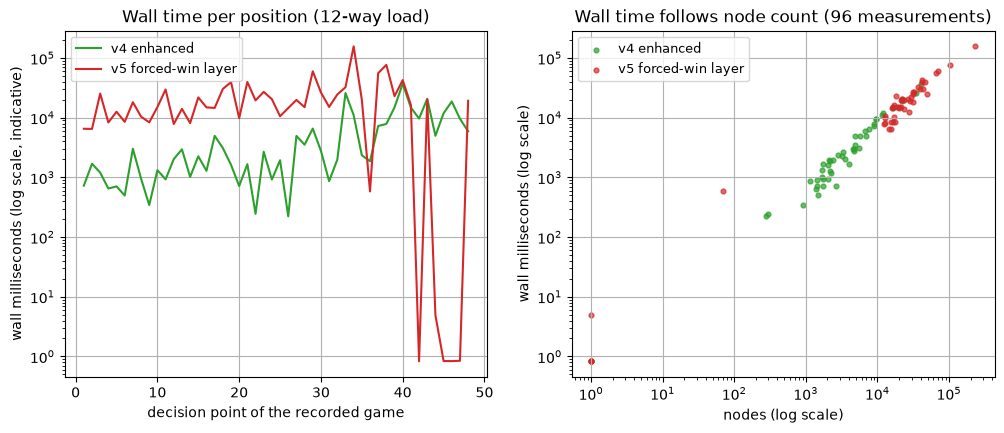

In [5]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v4"].ms for p in positions], color="tab:green", label="v4 enhanced")
ax.plot(positions, [per_prefix[p]["v5"].ms for p in positions], color="tab:red", label="v5 forced-win layer")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("wall milliseconds (log scale, indicative)")
ax.set_title("Wall time per position (12-way load)")
ax.grid(True)
ax.legend(fontsize=9)

v4_points = [(per_prefix[p]["v4"].nodes, per_prefix[p]["v4"].ms) for p in positions]
v5_points = [(per_prefix[p]["v5"].nodes, per_prefix[p]["v5"].ms) for p in positions]
ax2.scatter(*zip(*v4_points), s=12, color="tab:green", label="v4 enhanced", alpha=0.7)
ax2.scatter(*zip(*v5_points), s=12, color="tab:red", label="v5 forced-win layer", alpha=0.7)
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("nodes (log scale)")
ax2.set_ylabel("wall milliseconds (log scale)")
ax2.set_title("Wall time follows node count (96 measurements)")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()

## Iterative deepening under the budget

Stage 2 (defined in the primer at the top) is the budgeted deepening loop
(`connect6/vcf.py`): search the depth-3 floor, then re-search one ply deeper per step —
at most `V5_DEEPEN_STEPS = 2` extra plies — while the cumulative node count stays under
`V5_NODE_BUDGET = 12000`; a proven ±20,000 score would end the loop early. The budget is
checked *between* iterations: an iteration that has started always runs to completion,
so a position can overshoot — prefix 34's 220,243-node depth-4 tree above is exactly
that. `harness.probe_deepening` replays the loop over the common trajectory's 48 decision
points in isolation — stage 1 and the defence screen excluded, so this is the loop's own
cost, measured separately.

**Does deepening make the alpha-beta search itself cheaper?** In textbook iterative
deepening, yes: the previous iteration's best move is searched first (better move
ordering produces earlier cutoffs), and an aspiration window narrows the search bounds.
This engine's budget loop does neither — each step calls
`search_alpha_beta_with_quiescence` from scratch: the full `(MININT, MAXINT)` bounds, the
same evaluation-ordered candidate list at every depth, and no information carried
between steps (`connect6/search.py`). The precision inside each tree comes from
quiescence (v4's contribution, section 10); the deepening loop buys *depth*, not cheaper
cutoffs. The left panel measures that trade — each extra ply is a new,
independent tree —
and the right panel shows what the depth bought.

**The budget buys changed moves on ordinary positions, never changed verdicts.** The
loop's floor iteration is exactly v4's fixed tree (320,038 nodes, asserted below); 42 of
48 positions deepen to depth 4 (mean 26,021 nodes on top), nine of the cheapest continue
to depth 5 (mean 23,170 — lower than depth 4's mean precisely because only small trees
fit the budget twice), and six positions stop at the floor. Across both steps the loop
changes 30 moves and flips **zero** verdict bands: every verdict change v5 shows over v4
is a stage-1 proof. The probe's total (1,621,464 nodes) is deliberately not the
deployment's 1,415,330: the loop never runs at the six stage-1 answers (their would-be
trees cost 215,218 nodes), and the remaining 9,084-node difference is those six answers
themselves (75 nodes) plus the stage-1 searches and screen probes on the other 42
positions (9,009) that the probe excludes.

In [6]:
deepening = harness.probe_deepening(history, jobs=12)

floor_total = sum(steps[0].nodes for steps in deepening.values())
stage2_total = sum(sum(s.nodes for s in steps) for steps in deepening.values())
assert floor_total == totals["v4"]  # the loop's floor iteration is exactly v4's fixed tree

def band(score):
    return abs(score) >= 20000

stage1_positions = [36, 42, 44, 45, 46, 47]  # stage-1 positions: the forced-win search answers these before the loop runs
skipped = sum(sum(s.nodes for s in deepening[p]) for p in stage1_positions)

transitions = {"floor->d4": [0, 0, 0], "d4->d5": [0, 0, 0]}  # kept, changed, flipped
for steps in deepening.values():
    for i in range(1, len(steps)):
        key = "floor->d4" if i == 1 else "d4->d5"
        if band(steps[i].score) != band(steps[i - 1].score):
            transitions[key][2] += 1
        elif steps[i].move != steps[i - 1].move:
            transitions[key][1] += 1
        else:
            transitions[key][0] += 1

final_changes = sum(1 for s in deepening.values() if s[-1].move != s[0].move)
final_flips = sum(1 for s in deepening.values() if band(s[-1].score) != band(s[0].score))
d4_nodes = [s.nodes for steps in deepening.values() for s in steps if s.depth == 4]
d5_nodes = [s.nodes for steps in deepening.values() for s in steps if s.depth == 5]
reached_d4, reached_d5 = len(d4_nodes), len(d5_nodes)
floor_only = sum(1 for steps in deepening.values() if len(steps) == 1)

EXPECTED_DEEPENING = {
    "total": 1621464, "reached_d4": 42, "reached_d5": 9, "floor_only": 6,
    "d4_mean": 26021, "d5_mean": 23170, "skipped": 215218,
    "floor_to_d4": (11, 31, 0), "d4_to_d5": (5, 4, 0),
    "final_changes": 30, "final_flips": 0, "ledger_gap": 9084,
}
assert stage2_total == EXPECTED_DEEPENING["total"]
assert (reached_d4, reached_d5, floor_only) == (
    EXPECTED_DEEPENING["reached_d4"], EXPECTED_DEEPENING["reached_d5"], EXPECTED_DEEPENING["floor_only"])
assert sum(d4_nodes) // len(d4_nodes) == EXPECTED_DEEPENING["d4_mean"]
assert sum(d5_nodes) // len(d5_nodes) == EXPECTED_DEEPENING["d5_mean"]
assert skipped == EXPECTED_DEEPENING["skipped"]
assert tuple(transitions["floor->d4"]) == EXPECTED_DEEPENING["floor_to_d4"]
assert tuple(transitions["d4->d5"]) == EXPECTED_DEEPENING["d4_to_d5"]
assert (final_changes, final_flips) == (EXPECTED_DEEPENING["final_changes"], EXPECTED_DEEPENING["final_flips"])
assert totals["v5"] - (stage2_total - skipped) == EXPECTED_DEEPENING["ledger_gap"]

print(f"stage 2 in isolation: {stage2_total:,} nodes over 48 decision points "
      f"(the floor alone is {floor_total:,} — v4's whole game)")
print(f"deepening reached: d4 on {reached_d4}/48 (mean {sum(d4_nodes) // len(d4_nodes):,} nodes), "
      f"d5 on {reached_d5}/48 (mean {sum(d5_nodes) // len(d5_nodes):,} nodes); "
      f"{floor_only} positions stop at the floor")
print(f"per-step transitions (kept, changed, flipped): floor->d4 {tuple(transitions['floor->d4'])}, "
      f"d4->d5 {tuple(transitions['d4->d5'])}")
print(f"floor->final: {final_changes} quiet move changes, {final_flips} verdict flips — "
      f"all six of v5's flips over v4 are stage-1 proofs")
print(f"ledger: probe {stage2_total:,} - never-run {skipped:,} + gap {EXPECTED_DEEPENING['ledger_gap']:,} "
      f"(six stage-1 answers = 75 nodes, stage-1 misses + screens = 9,009) = v5's {totals['v5']:,}")

stage 2 in isolation: 1,621,464 nodes over 48 decision points (the floor alone is 320,038 — v4's whole game)
deepening reached: d4 on 42/48 (mean 26,021 nodes), d5 on 9/48 (mean 23,170 nodes); 6 positions stop at the floor
per-step transitions (kept, changed, flipped): floor->d4 (11, 31, 0), d4->d5 (5, 4, 0)
floor->final: 30 quiet move changes, 0 verdict flips — all six of v5's flips over v4 are stage-1 proofs
ledger: probe 1,621,464 - never-run 215,218 + gap 9,084 (six stage-1 answers = 75 nodes, stage-1 misses + screens = 9,009) = v5's 1,415,330


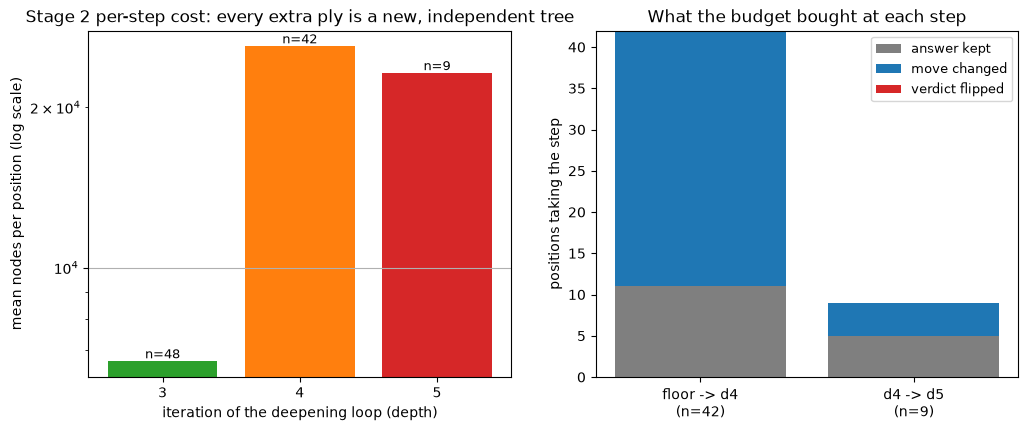

In [7]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
depths = (3, 4, 5)
step_nodes = {d: [s.nodes for steps in deepening.values() for s in steps if s.depth == d] for d in depths}
means = [sum(v) / len(v) for v in step_nodes.values()]
bars = ax.bar([str(d) for d in depths], means, color=["tab:green", "tab:orange", "tab:red"])
ax.set_yscale("log")
for bar, d in zip(bars, depths):
    ax.annotate(f"n={len(step_nodes[d])}", (bar.get_x() + bar.get_width() / 2, means[d - 3]),
                ha="center", va="bottom", fontsize=9)
ax.set_xlabel("iteration of the deepening loop (depth)")
ax.set_ylabel("mean nodes per position (log scale)")
ax.set_title("Stage 2 per-step cost: every extra ply is a new, independent tree")
ax.grid(True, axis="y")

labels = [f"floor -> d4\n(n={reached_d4})", f"d4 -> d5\n(n={reached_d5})"]
kept = [transitions["floor->d4"][0], transitions["d4->d5"][0]]
changed = [transitions["floor->d4"][1], transitions["d4->d5"][1]]
flipped = [transitions["floor->d4"][2], transitions["d4->d5"][2]]
ax2.bar(labels, kept, color="tab:gray", label="answer kept")
ax2.bar(labels, changed, bottom=kept, color="tab:blue", label="move changed")
ax2.bar(labels, flipped, bottom=[k + c for k, c in zip(kept, changed)], color="tab:red", label="verdict flipped")
ax2.set_ylabel("positions taking the step")
ax2.set_title("What the budget bought at each step")
ax2.legend(fontsize=9)
plt.show()

## Reading the results

- **The layer finds wins the v4 engine never recognizes** — in the closing stretch of a
  game the v4 engine played to a 48-move standstill, five positions held proven forced
  wins for the side to move (both colors); stage 1 answers each in a single node, and the
  stage-1 search proves a sixth (prefix 36) in 70 nodes — a longer forced sequence,
  still cheaper than any ordinary move. The v4 engine played through all six without
  recognizing them.
- **The cost is real and unevenly distributed** — 4.4x v4's mean nodes over the game:
  ordinary positions pay the deepening budget, and the sharpest position pays the
  budget's overshoot (prefix 34: the floor tree is just below 12,000, so a depth-4
  iteration runs to completion at 220,243 nodes — 94% of the 233,374 peak; stage 1 and
  the defence screen account for the remaining 1,519). The one-node answers cost
  nothing at all: a proven win is cheaper than an ordinary move.
- **Move changes cluster away from the verdict changes** — 35 of 48 moves differ: 30 are
  the deepening loop's choices on ordinary positions, five are the stage-1 answers
  themselves (six answers, one coinciding with v4's move). Yet only six answers move into
  the proven-win band, and all six are stage-1 proofs: the budget buys better ordinary
  moves, the layer buys verdicts.
- **The budget buys changed moves, never changed verdicts** — the deepening probe above
  measures stage 2 in isolation: 1,621,464 nodes, 30 changed moves, zero verdict changes
  at either step. Iterative deepening here buys depth with nodes, not cheaper cutoffs —
  each step is a fresh, independent tree (full bounds, nothing carried over).
- The skills themselves — forced wins in 1-3 turns, defence, opening consistency — are
  the position battery's business (section 11.3); this notebook is the layer's
  cost-and-behaviour record. Full discussion: docs/EVALUATION.md, sections 11.1, 11.3
  and 11.4.